# Cointegration-Based Pair Trading Research Framework — NIFTY 500

**Strategy.** Statistical arbitrage on Indian equities using Engle–Granger cointegration
to identify mean-reverting pairs, rolling OLS to track the hedge ratio, and a
z-score-driven entry/exit rule with stop-loss and beta-neutral sizing.

**Pipeline.**

1. Pull the NIFTY 500 universe (Jan-2022 constituents) from `yfinance`.
2. Clean / align the panel; keep names with sufficient history.
3. **In-sample (2022-01-01 → 2025-01-31)** — Engle–Granger on every candidate pair, p < 0.05, rank by p-value.
4. Pick regression direction (X vs Y) by minimising `SE(intercept) / SE(residuals)`.
5. Run rolling OLS at 100 / 150 / 200 / 252-day windows; derive residuals and rolling z.
6. Event-driven backtest: enter at |z| ≥ 2.5, exit at |z| ≤ 1, stop at |z| ≥ 3, beta-neutral.
7. Compare windows in-sample; pick the winner; run **out-of-sample (2025-02-01 → 2026-06-15)** forward test.
8. Beta-stability inspection, full plotting suite, CSV exports, research report.

**Look-ahead discipline.** Pair *selection* uses in-sample data only. Out-of-sample
trades the same pair list with rolling regression rolling forward — the OOS window
never informs which pairs are traded.

## 1 — Environment & Imports

In [4]:
# Core
import os, sys, math, warnings, itertools, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Stats / econometrics
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from statsmodels.regression.rolling import RollingOLS

# Data / parallelism
import yfinance as yf
from joblib import Parallel, delayed
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"yfinance {yf.__version__}")

pandas  2.2.3
numpy   1.26.4
yfinance 0.2.66


## 2 — Configuration

Everything tweakable lives in this block. Re-running the notebook with different
settings should require touching nothing below this cell.

In [5]:
class Config:
    # ---- Paths ----
    UNIVERSE_CSV = r"data/ind_nifty500list_jan_28_2022.csv"   # adjust if elsewhere
    OUTPUT_DIR   = Path("./pair_trading_output")
    OUTPUT_DIR.mkdir(exist_ok=True)

    # ---- Universe / data ----
    TICKER_SUFFIX     = ".NS"          # NSE on Yahoo
    DATA_START        = "2021-01-01"   # need ~1y pre-roll for the longest window
    DATA_END          = "2026-06-15"
    MIN_HISTORY_DAYS  = 750            # drop thinly-traded / new listings
    MIN_PRICE         = 10.0           # avoid pennystocks numerically blowing up
    MAX_MISSING_RATIO = 0.02           # > 2% NaNs → drop

    # ---- Sample split ----
    IS_START  = "2022-01-01"
    IS_END    = "2025-01-31"
    OOS_START = "2025-02-01"
    OOS_END   = "2026-06-15"

    # ---- Pair selection ----
    COINT_PVALUE_MAX  = 0.05
    SAME_INDUSTRY_ONLY = True          # pragmatic pre-filter (set False for full N*(N-1)/2 scan)
    MAX_PAIRS_KEEP    = 200            # after p-value ranking, cap shortlist

    # ---- Rolling regression windows ----
    REG_WINDOWS = [100, 150, 200, 252]

    # ---- Signal thresholds ----
    Z_ENTRY = 2.5
    Z_EXIT  = 1.0
    Z_STOP  = 3.0

    # ---- Backtest ----
    CAPITAL_PER_PAIR = 500_000          # INR
    TXN_COST_BPS     = 10               # 10 bps per leg per side (round-trip ~ 40 bps)
    MAX_HOLD_DAYS    = 60               # hard timeout — protects against permanent regime breaks

    # ---- Misc ----
    N_JOBS  = -1                        # all cores for parallel scan
    SEED    = 42
    RFR     = 0.065                     # ~Indian risk-free for Sharpe scaling

cfg = Config()
np.random.seed(cfg.SEED)
print("Output dir:", cfg.OUTPUT_DIR.resolve())

Output dir: D:\Coading\Pairs_Trading\pair_trading_output


## 3 — Universe Loading

In [6]:
uni = pd.read_csv(cfg.UNIVERSE_CSV)
uni.columns = [c.strip() for c in uni.columns]
uni["Symbol"]   = uni["Symbol"].str.strip()
uni["Industry"] = uni["Industry"].str.strip()
uni["Ticker"]   = uni["Symbol"] + cfg.TICKER_SUFFIX

print(f"Universe size: {len(uni)}")
print(f"Industries   : {uni['Industry'].nunique()}")
uni.head()

Universe size: 503
Industries   : 20


,Sl.No,Company Name,Industry,Symbol,Ticker
0,1,3M India Ltd.,CONSUMER GOODS,3MINDIA,3MINDIA.NS
1,2,ABB India Ltd.,INDUSTRIAL MANUFACTURING,ABB,ABB.NS
2,3,ABB Power Products and Systems India Ltd.,INDUSTRIAL MANUFACTURING,POWERINDIA,POWERINDIA.NS
3,4,ACC Ltd.,CEMENT & CEMENT PRODUCTS,ACC,ACC.NS
4,5,AIA Engineering Ltd.,INDUSTRIAL MANUFACTURING,AIAENG,AIAENG.NS


## 4 — Bulk Price Download

`yfinance` returns a multi-level column DataFrame when given a list of tickers.
We pull `Close` (already adjusted in current yfinance versions; we use `auto_adjust=True`
to be explicit) and reshape to a flat `Date × Ticker` matrix.

In [7]:
def download_prices(tickers, start, end, batch=80):
    """Batched download to avoid Yahoo rate limits."""
    chunks = []
    for i in tqdm(range(0, len(tickers), batch), desc="yfinance batches"):
        sub = tickers[i:i+batch]
        df = yf.download(
            sub, start=start, end=end,
            auto_adjust=True, progress=False,
            threads=True, group_by="column",
        )
        if df.empty:
            continue
        # When >1 ticker: columns are MultiIndex (field, ticker). We want 'Close'.
        if isinstance(df.columns, pd.MultiIndex):
            df = df["Close"]
        else:
            # single ticker case
            df = df[["Close"]].rename(columns={"Close": sub[0]})
        chunks.append(df)
    out = pd.concat(chunks, axis=1)
    out = out.loc[:, ~out.columns.duplicated()]
    return out.sort_index()

prices_raw = download_prices(uni["Ticker"].tolist(), cfg.DATA_START, cfg.DATA_END)
print("Raw shape:", prices_raw.shape)
prices_raw.tail(3)

yfinance batches:   0%|          | 0/7 [00:00<?, ?it/s]


5 Failed downloads:
['ANGELBRKG.NS', 'AEGISCHEM.NS', 'AMARAJABAT.NS', 'ADANITRANS.NS']: YFTzMissingError('possibly delisted; no timezone found')
['AKZOINDIA.NS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-06-15) (Yahoo error = "No data found, symbol may be delisted")')

7 Failed downloads:
['EQUITAS.NS', 'CENTURYTEX.NS', 'GEPIL.NS', 'CADILAHC.NS', 'DHANI.NS', 'BURGERKING.NS', 'GMRINFRA.NS']: YFTzMissingError('possibly delisted; no timezone found')

7 Failed downloads:
['ISEC.NS', 'IDFC.NS', 'IIFLWAM.NS', 'HDFC.NS', 'IBULHSGFIN.NS']: YFTzMissingError('possibly delisted; no timezone found')
['GSPL.NS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-06-15)')
['GUJGASLTD.NS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-06-15) (Yahoo error = "Data doesn\'t exist for startDate = 1609439400, endDate = 1781461800")')

12 Failed downloads:
['KALPATPOWR.NS', 'INOXLEISUR.NS

Raw shape: (1347, 502)


Ticker,3MINDIA.NS,AARTIDRUGS.NS,AARTIIND.NS,AAVAS.NS,ABB.NS,ABBOTINDIA.NS,ABCAPITAL.NS,ABFRL.NS,ACC.NS,ADANIENT.NS,...,WELCORP.NS,WELSPUNIND.NS,WESTLIFE.NS,WHIRLPOOL.NS,WIPRO.NS,WOCKPHARMA.NS,YESBANK.NS,ZEEL.NS,ZENSARTECH.NS,ZYDUSWELL.NS
Date,,,,,,,,,,,,,,,,,,,,,
2026-06-10,"31,129.1758",371.9000,433.6500,"1,299.6000","6,721.8677","25,850.1035",342.7000,58.7600,"1,308.6281","2,929.7900",...,"1,365.8647",NaN,429.1032,781.0500,176.9095,"1,833.0000",22.6000,102.9300,446.4092,495.7596
2026-06-11,"30,720.1016",367.7500,427.8500,"1,328.2000","6,640.8218","25,469.0215",336.6000,58.2400,"1,296.2000","2,907.5000",...,"1,384.8019",NaN,438.2469,769.3500,175.3672,"1,923.8000",22.2200,111.4500,432.3018,499.3524
2026-06-12,"31,099.6035",371.7000,440.6000,"1,405.7000","6,691.7222","25,679.1055",358.1000,59.9000,"1,336.6000","2,921.6001",...,"1,397.6592",NaN,445.5419,769.9500,178.1059,"1,938.0000",23.0200,112.6000,442.0647,504.9912


## 5 — Cleaning & Alignment

In [8]:
def clean_panel(prices, min_days, min_price, max_missing):
    p = prices.copy()
    # forward-fill tiny gaps (holidays), but drop names with too many holes
    miss = p.isna().mean()
    keep_missing = miss[miss <= max_missing].index
    p = p[keep_missing]

    # require minimum history
    first_valid = p.apply(lambda s: s.first_valid_index())
    span_days   = (p.index[-1] - first_valid).dt.days
    keep_hist   = span_days[span_days >= min_days * 1.4].index   # calendar→trading buffer
    p = p[keep_hist]

    # drop names with median price below floor
    keep_price = p.median()[p.median() >= min_price].index
    p = p[keep_price]

    # gentle ffill (≤ 3 days) — anything wider is a real data hole
    p = p.ffill(limit=3)

    # restrict to common-date panel
    p = p.dropna(how="any")
    return p

prices = clean_panel(
    prices_raw,
    min_days       = cfg.MIN_HISTORY_DAYS,
    min_price      = cfg.MIN_PRICE,
    max_missing    = cfg.MAX_MISSING_RATIO,
)
print(f"Cleaned panel: {prices.shape[1]} tickers × {prices.shape[0]} trading days")
print(f"Date range   : {prices.index.min().date()} → {prices.index.max().date()}")

# Keep only universe rows that survived the cleaning
uni_clean = uni[uni["Ticker"].isin(prices.columns)].reset_index(drop=True)
print(f"Surviving universe size: {len(uni_clean)}")

Cleaned panel: 447 tickers × 1347 trading days
Date range   : 2021-01-01 → 2026-06-12
Surviving universe size: 448


## 6 — Pair Candidate Generation

`SAME_INDUSTRY_ONLY=True` is on by default. With 500 names that cuts the candidate
set from ~125k to a few thousand and concentrates the scan on economically plausible
pairs — flip the flag if you want the brute-force version.

In [9]:
def candidate_pairs(universe_df, same_industry=True):
    if same_industry:
        pairs = []
        for ind, grp in universe_df.groupby("Industry"):
            tickers = grp["Ticker"].tolist()
            pairs.extend(itertools.combinations(tickers, 2))
        return pairs
    else:
        return list(itertools.combinations(universe_df["Ticker"].tolist(), 2))

pair_candidates = candidate_pairs(uni_clean, same_industry=cfg.SAME_INDUSTRY_ONLY)
print(f"Candidate pairs: {len(pair_candidates):,}")

Candidate pairs: 8,059


## 7 — In-Sample Engle–Granger Scan

The Engle–Granger test is a regression-plus-ADF on residuals. We run it on **log prices**
(standard for cointegration on equities — turns multiplicative trends into additive ones).
Pairs with p < 0.05 survive and are ranked by p-value.

In [10]:
log_prices    = np.log(prices)
log_prices_is = log_prices.loc[cfg.IS_START:cfg.IS_END]

def coint_test(y, x):
    try:
        s, p, _ = coint(y, x, trend="c", autolag="AIC")
        return s, p
    except Exception:
        return np.nan, np.nan

def scan_pair(t1, t2, panel):
    y = panel[t1].values
    x = panel[t2].values
    s, p = coint_test(y, x)
    return (t1, t2, s, p)

print(f"Running Engle–Granger on {len(pair_candidates):,} pairs in parallel ...")
t0 = time.time()
results = Parallel(n_jobs=cfg.N_JOBS, batch_size=64, verbose=0)(
    delayed(scan_pair)(a, b, log_prices_is) for a, b in tqdm(pair_candidates)
)
print(f"  done in {time.time()-t0:,.1f}s")

coint_df = pd.DataFrame(results, columns=["T1", "T2", "coint_stat", "coint_pvalue"])
coint_df = coint_df.dropna()
print(f"Tested pairs : {len(coint_df):,}")

sig = coint_df[coint_df["coint_pvalue"] < cfg.COINT_PVALUE_MAX].copy()
sig = sig.sort_values("coint_pvalue").head(cfg.MAX_PAIRS_KEEP).reset_index(drop=True)
print(f"Significant (p<{cfg.COINT_PVALUE_MAX}): {len(sig)}   (showing top {cfg.MAX_PAIRS_KEEP})")
sig.head(10)

Running Engle–Granger on 8,059 pairs in parallel ...


  0%|          | 0/8059 [00:00<?, ?it/s]

  done in 37.4s
Tested pairs : 8,059
Significant (p<0.05): 200   (showing top 200)


,T1,T2,coint_stat,coint_pvalue
0,ASTERDM.NS,MAXHEALTH.NS,-6.0139,0.0000
1,BANKINDIA.NS,UNIONBANK.NS,-5.1499,0.0001
2,CYIENT.NS,SONATSOFTW.NS,-5.1018,0.0001
3,HCLTECH.NS,PERSISTENT.NS,-5.0248,0.0001
4,BLISSGVS.NS,CAPLIPOINT.NS,-4.9410,0.0002
5,KOTAKBANK.NS,SBICARD.NS,-4.9117,0.0002
6,BRIGADE.NS,PRESTIGE.NS,-4.8907,0.0003
7,PGHH.NS,RESPONIND.NS,-4.8890,0.0003
8,AJANTPHARM.NS,FDC.NS,-4.8712,0.0003
9,SUNDARMFIN.NS,TATAINVEST.NS,-4.8206,0.0003


## 8 — Regression Direction Choice

For every cointegrated pair we run OLS both ways and pick the orientation with the
**lower** `SE(intercept) / SE(residuals)` ratio — this is the standard Engle–Granger
heuristic for the more stable cointegrating direction.

In [11]:
def fit_pair_direction(t1, t2, panel):
    # Try both: Y=t1,X=t2  and  Y=t2,X=t1
    out = []
    for y_sym, x_sym in [(t1, t2), (t2, t1)]:
        y = panel[y_sym].values
        x = panel[x_sym].values
        X = sm.add_constant(x)
        try:
            res = sm.OLS(y, X).fit()
            alpha, beta = res.params
            se_alpha   = res.bse[0]
            resid_std  = np.std(res.resid, ddof=2)
            ratio      = se_alpha / resid_std if resid_std > 0 else np.inf
            out.append((y_sym, x_sym, alpha, beta, se_alpha, resid_std, ratio))
        except Exception:
            out.append((y_sym, x_sym, np.nan, np.nan, np.nan, np.nan, np.inf))
    out.sort(key=lambda r: r[-1])     # ascending error ratio
    best = out[0]
    return dict(Y=best[0], X=best[1], alpha=best[2], beta=best[3],
                se_alpha=best[4], resid_std=best[5], error_ratio=best[6])

dirs = []
for _, row in tqdm(sig.iterrows(), total=len(sig), desc="direction"):
    d = fit_pair_direction(row["T1"], row["T2"], log_prices_is)
    d.update(coint_stat=row["coint_stat"], coint_pvalue=row["coint_pvalue"])
    dirs.append(d)

pairs_df = pd.DataFrame(dirs)
pairs_df = pairs_df[["Y", "X", "alpha", "beta", "error_ratio",
                     "coint_stat", "coint_pvalue"]]
pairs_df.to_csv(cfg.OUTPUT_DIR / "cointegrated_pairs.csv", index=False)
print(f"Saved → {cfg.OUTPUT_DIR/'cointegrated_pairs.csv'}")
pairs_df.head(10)

direction:   0%|          | 0/200 [00:00<?, ?it/s]

Saved → pair_trading_output\cointegrated_pairs.csv


,Y,X,alpha,beta,error_ratio,coint_stat,coint_pvalue
0,MAXHEALTH.NS,ASTERDM.NS,1.4721,0.8929,0.4870,-6.0139,0.0000
1,BANKINDIA.NS,UNIONBANK.NS,0.9954,0.7763,0.3073,-5.1499,0.0001
2,CYIENT.NS,SONATSOFTW.NS,1.3856,0.9494,0.5338,-5.1018,0.0001
3,HCLTECH.NS,PERSISTENT.NS,2.3130,0.5927,0.6939,-5.0248,0.0001
4,BLISSGVS.NS,CAPLIPOINT.NS,0.4198,0.5954,0.6212,-4.9410,0.0002
5,KOTAKBANK.NS,SBICARD.NS,4.1002,0.2681,2.7992,-4.9117,0.0002
6,BRIGADE.NS,PRESTIGE.NS,1.6296,0.6966,0.4186,-4.8907,0.0003
7,PGHH.NS,RESPONIND.NS,8.3002,0.2416,0.5348,-4.8890,0.0003
8,FDC.NS,AJANTPHARM.NS,0.3982,0.7354,0.7518,-4.8712,0.0003
9,SUNDARMFIN.NS,TATAINVEST.NS,4.8934,0.5367,0.3346,-4.8206,0.0003


## 9 — Rolling Regression Framework

For each surviving pair and each window length we compute rolling α, β and
residuals on **log prices** over the full sample (IS + OOS). Z-score is the residual
normalised by the rolling residual std within the same window.

In [12]:
def rolling_pair(y_sym, x_sym, window, panel):
    """Return DataFrame with alpha, beta, resid, sigma, z indexed by date."""
    y = panel[y_sym]
    x = panel[x_sym]
    X = sm.add_constant(x)
    rmod = RollingOLS(endog=y, exog=X, window=window).fit()
    params = rmod.params               # cols: ['const', x_sym]
    alpha = params["const"]
    beta  = params[x_sym]
    resid = y - (alpha + beta * x)
    sigma = resid.rolling(window).std()
    z     = resid / sigma
    return pd.DataFrame({
        "alpha": alpha, "beta": beta,
        "resid": resid, "sigma": sigma, "z": z,
    })

def rolling_all_windows(pair_row, windows, panel):
    return {w: rolling_pair(pair_row["Y"], pair_row["X"], w, panel) for w in windows}

# Pre-compute for every surviving pair × every window — used for both IS and OOS.
print("Building rolling stats for all surviving pairs across all windows ...")
rolling_store = {}
for _, row in tqdm(pairs_df.iterrows(), total=len(pairs_df)):
    key = (row["Y"], row["X"])
    rolling_store[key] = rolling_all_windows(row, cfg.REG_WINDOWS, log_prices)
print(f"Stored rolling stats for {len(rolling_store)} pairs.")

Building rolling stats for all surviving pairs across all windows ...


  0%|          | 0/200 [00:00<?, ?it/s]

Stored rolling stats for 200 pairs.


## 10 — Event-Driven Backtest Engine

Each pair is traded independently. Within a pair, no overlap. Across pairs, fully
parallel positions. Costs charged at entry and exit on both legs. Position sized so
that the Y-leg uses ≈ half the per-pair capital and the X-leg holds `β` shares per
share of Y (beta-neutral). PnL is computed on the **price level** moves of the two
legs, not on the log-price spread.

In [13]:
def size_positions(y_price, x_price, beta, capital):
    """Beta-neutral sizing: qty_x = beta * qty_y. Allocate ~half capital each side."""
    if not np.isfinite(beta) or beta == 0:
        return 0, 0
    # nominal per leg ≈ capital/2
    qty_y = int((capital * 0.5) // y_price)
    qty_x = int(round(qty_y * abs(beta)))
    return qty_y, qty_x

def backtest_pair(y_sym, x_sym, window, prices_lvl, rolling, start, end, cfg):
    """Single-pair, single-window backtest."""
    df = rolling[window].loc[start:end].copy()
    df["Y_px"] = prices_lvl[y_sym].reindex(df.index)
    df["X_px"] = prices_lvl[x_sym].reindex(df.index)
    df = df.dropna(subset=["alpha", "beta", "z", "Y_px", "X_px"])

    trades = []
    in_pos = False
    side   = 0      # +1 long-spread (long Y, short X) ; -1 short-spread
    entry  = None

    cost_rate = cfg.TXN_COST_BPS / 1e4

    for dt, r in df.iterrows():
        z = r["z"]
        if not in_pos:
            if z <= -cfg.Z_ENTRY:
                side = +1
            elif z >= cfg.Z_ENTRY:
                side = -1
            else:
                continue
            qy, qx = size_positions(r["Y_px"], r["X_px"], r["beta"], cfg.CAPITAL_PER_PAIR)
            if qy == 0 or qx == 0:
                continue
            entry = dict(
                date=dt, z=z, beta=r["beta"], alpha=r["alpha"],
                yp=r["Y_px"], xp=r["X_px"], qy=qy, qx=qx, side=side,
            )
            in_pos = True
            continue

        # in position
        hold = (dt - entry["date"]).days
        stop = ( (entry["side"] == +1 and z <= -cfg.Z_STOP) or
                 (entry["side"] == -1 and z >=  cfg.Z_STOP) )
        target = ( (entry["side"] == +1 and z >= -cfg.Z_EXIT) or
                   (entry["side"] == -1 and z <=  cfg.Z_EXIT) )
        timeout = hold >= cfg.MAX_HOLD_DAYS
        last_bar = dt == df.index[-1]

        if stop or target or timeout or last_bar:
            # PnL on price levels — beta-neutral, side-aware
            dy = (r["Y_px"] - entry["yp"]) * entry["qy"] * entry["side"]
            dx = (entry["xp"] - r["X_px"]) * entry["qx"] * entry["side"]
            gross = dy + dx
            notional = entry["yp"]*entry["qy"] + entry["xp"]*entry["qx"]
            notional_exit = r["Y_px"]*entry["qy"] + r["X_px"]*entry["qx"]
            cost  = (notional + notional_exit) * cost_rate
            net   = gross - cost
            ret   = net / cfg.CAPITAL_PER_PAIR
            reason = ("stop" if stop else "target" if target else
                      "timeout" if timeout else "eod")
            trades.append(dict(
                Y=y_sym, X=x_sym, window=window,
                entry_date=entry["date"], exit_date=dt,
                side="LONG_SPREAD" if entry["side"] == +1 else "SHORT_SPREAD",
                entry_z=entry["z"], exit_z=z,
                entry_y=entry["yp"], exit_y=r["Y_px"],
                entry_x=entry["xp"], exit_x=r["X_px"],
                alpha=entry["alpha"], beta=entry["beta"],
                qy=entry["qy"], qx=entry["qx"],
                holding_days=hold, gross_pnl=gross, cost=cost,
                net_pnl=net, ret=ret, exit_reason=reason,
            ))
            in_pos = False
            entry = None
    return pd.DataFrame(trades)

def run_book(pairs, window, start, end, cfg):
    out = []
    for _, row in tqdm(pairs.iterrows(), total=len(pairs), desc=f"bt w={window}", leave=False):
        tdf = backtest_pair(row["Y"], row["X"], window, prices,
                            rolling_store[(row["Y"], row["X"])],
                            start, end, cfg)
        if not tdf.empty:
            out.append(tdf)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

## 11 — Performance Analytics

In [14]:
def equity_curve(trades, start, end, capital_total):
    """Mark-to-cash daily equity by stamping net PnL on exit date, summed across pairs."""
    if trades.empty:
        idx = prices.loc[start:end].index
        return pd.Series(capital_total, index=idx, name="equity")
    daily_pnl = trades.groupby("exit_date")["net_pnl"].sum()
    idx = prices.loc[start:end].index
    series = daily_pnl.reindex(idx, fill_value=0.0).cumsum() + capital_total
    series.name = "equity"
    return series

def perf_metrics(trades, equity, rfr=0.065):
    if trades.empty:
        return {k: np.nan for k in
                ["n_trades","win_rate","avg_ret","total_pnl","net_pnl",
                 "profit_factor","sharpe","sortino","max_dd","avg_hold"]}
    rets = equity.pct_change().fillna(0)
    excess = rets - rfr/252
    sharpe  = np.sqrt(252) * excess.mean() / (excess.std() + 1e-12)
    downside = excess[excess < 0]
    sortino = np.sqrt(252) * excess.mean() / (downside.std() + 1e-12) if len(downside) else np.nan
    roll_max = equity.cummax()
    dd = (equity / roll_max - 1).min()

    wins   = trades[trades["net_pnl"] > 0]["net_pnl"].sum()
    losses = -trades[trades["net_pnl"] <= 0]["net_pnl"].sum()
    pf = wins / losses if losses > 0 else np.inf

    return dict(
        n_trades      = len(trades),
        win_rate      = (trades["net_pnl"] > 0).mean(),
        avg_ret       = trades["ret"].mean(),
        total_pnl     = trades["gross_pnl"].sum(),
        net_pnl       = trades["net_pnl"].sum(),
        profit_factor = pf,
        sharpe        = sharpe,
        sortino       = sortino,
        max_dd        = dd,
        avg_hold      = trades["holding_days"].mean(),
    )

def pair_breakdown(trades):
    if trades.empty:
        return pd.DataFrame()
    rows = []
    for (y, x), g in trades.groupby(["Y", "X"]):
        m = dict(Y=y, X=x,
                 n_trades=len(g),
                 win_rate=(g["net_pnl"] > 0).mean(),
                 avg_ret=g["ret"].mean(),
                 total_pnl=g["gross_pnl"].sum(),
                 net_pnl=g["net_pnl"].sum(),
                 avg_hold=g["holding_days"].mean())
        wins   = g[g["net_pnl"] > 0]["net_pnl"].sum()
        losses = -g[g["net_pnl"] <= 0]["net_pnl"].sum()
        m["profit_factor"] = wins/losses if losses > 0 else np.inf
        # per-pair Sharpe from trade returns (not daily)
        m["sharpe"] = np.sqrt(252/max(g["holding_days"].mean(),1)) * \
                       g["ret"].mean() / (g["ret"].std() + 1e-12)
        rows.append(m)
    return pd.DataFrame(rows).sort_values("sharpe", ascending=False)

## 12 — In-Sample Comparison Across Windows

Run the backtest for **every regression window** on the in-sample period and pick
the winner by Sharpe-with-tiebreak-on-profit-factor.

In [15]:
is_results = {}
for w in cfg.REG_WINDOWS:
    trades = run_book(pairs_df, w, cfg.IS_START, cfg.IS_END, cfg)
    cap_total = cfg.CAPITAL_PER_PAIR * max(len(pairs_df), 1)
    eq     = equity_curve(trades, cfg.IS_START, cfg.IS_END, cap_total)
    metr   = perf_metrics(trades, eq, cfg.RFR)
    is_results[w] = dict(trades=trades, equity=eq, metrics=metr)
    print(f"window={w:>3d}  trades={metr['n_trades']:>4d}  "
          f"sharpe={metr['sharpe']:>5.2f}  pf={metr['profit_factor']:>5.2f}  "
          f"dd={metr['max_dd']:>6.1%}  net_pnl={metr['net_pnl']:>14,.0f}")

is_compare = pd.DataFrame({w: is_results[w]["metrics"] for w in cfg.REG_WINDOWS}).T
is_compare.index.name = "window"
display(is_compare)

best_window = is_compare.sort_values(
    ["sharpe", "profit_factor"], ascending=False
).index[0]
print(f"\n>>> Best regression window (in-sample): {best_window} <<<")

bt w=100:   0%|          | 0/200 [00:00<?, ?it/s]

window=100  trades=2534  sharpe=-4.08  pf= 1.36  dd= -1.1%  net_pnl=     5,779,477


bt w=150:   0%|          | 0/200 [00:00<?, ?it/s]

window=150  trades=1735  sharpe=-4.59  pf= 1.58  dd= -1.6%  net_pnl=     6,429,144


bt w=200:   0%|          | 0/200 [00:00<?, ?it/s]

window=200  trades=1472  sharpe=-7.73  pf= 1.73  dd= -0.4%  net_pnl=     5,485,287


bt w=252:   0%|          | 0/200 [00:00<?, ?it/s]

window=252  trades=1030  sharpe=-6.60  pf= 2.40  dd= -0.3%  net_pnl=     6,288,938


,n_trades,win_rate,avg_ret,total_pnl,net_pnl,profit_factor,sharpe,sortino,max_dd,avg_hold
window,,,,,,,,,,
100,"2,534.0000",0.4613,0.0046,"8,305,322.7436","5,779,477.2261",1.3558,-4.0818,-5.2070,-0.0113,9.4700
150,"1,735.0000",0.5003,0.0074,"8,180,455.6474","6,429,144.2985",1.5775,-4.5931,-6.6265,-0.0164,11.1118
200,"1,472.0000",0.4565,0.0075,"6,722,858.2704","5,485,287.1856",1.7336,-7.7254,-14.1680,-0.0040,10.9518
252,"1,030.0000",0.5010,0.0122,"7,172,866.6694","6,288,938.0764",2.3982,-6.6008,-23.0695,-0.0027,11.4078



>>> Best regression window (in-sample): 100 <<<


## 13 — Out-of-Sample Forward Test

In [16]:
oos_trades  = run_book(pairs_df, best_window, cfg.OOS_START, cfg.OOS_END, cfg)
cap_total   = cfg.CAPITAL_PER_PAIR * max(len(pairs_df), 1)
oos_equity  = equity_curve(oos_trades, cfg.OOS_START, cfg.OOS_END, cap_total)
oos_metrics = perf_metrics(oos_trades, oos_equity, cfg.RFR)

print("Out-of-sample metrics @ window =", best_window)
for k, v in oos_metrics.items():
    print(f"  {k:>14s} = {v}")

# Persist trade log + pair-level summary
all_trades = pd.concat(
    [is_results[best_window]["trades"].assign(period="IS"),
     oos_trades.assign(period="OOS")],
    ignore_index=True,
)
all_trades.to_csv(cfg.OUTPUT_DIR / "trade_log.csv", index=False)

pair_sum_is  = pair_breakdown(is_results[best_window]["trades"]).assign(period="IS")
pair_sum_oos = pair_breakdown(oos_trades).assign(period="OOS")
pair_summary = pd.concat([pair_sum_is, pair_sum_oos], ignore_index=True)
pair_summary.to_csv(cfg.OUTPUT_DIR / "pair_summary.csv", index=False)

print(f"\nSaved → {cfg.OUTPUT_DIR/'trade_log.csv'}")
print(f"Saved → {cfg.OUTPUT_DIR/'pair_summary.csv'}")

bt w=100:   0%|          | 0/200 [00:00<?, ?it/s]

Out-of-sample metrics @ window = 100
        n_trades = 1806
        win_rate = 0.4263565891472868
         avg_ret = 0.0034500287268972372
       total_pnl = 5420054.798854828
         net_pnl = 3115375.940388208
   profit_factor = 1.1939736010465347
          sharpe = -0.7206108336995288
         sortino = -0.8585341175841444
          max_dd = -0.047232918778061905
        avg_hold = 8.386489479512734

Saved → pair_trading_output\trade_log.csv
Saved → pair_trading_output\pair_summary.csv


## 14 — Out-of-Sample Cointegration Stability

Re-run Engle–Granger on the OOS window itself for the surviving pairs — a pair that
*was* cointegrated 2022→2025 but isn't 2025→2026 is a regime break candidate.

In [17]:
log_prices_oos = log_prices.loc[cfg.OOS_START:cfg.OOS_END]
stab_rows = []
for _, row in pairs_df.iterrows():
    y_oos = log_prices_oos[row["Y"]].dropna()
    x_oos = log_prices_oos[row["X"]].dropna()
    common = y_oos.index.intersection(x_oos.index)
    if len(common) < 60:
        continue
    s, p = coint_test(y_oos.loc[common].values, x_oos.loc[common].values)

    # OOS beta on the OOS window
    Xm = sm.add_constant(x_oos.loc[common].values)
    try:
        b_oos = sm.OLS(y_oos.loc[common].values, Xm).fit().params[1]
    except Exception:
        b_oos = np.nan
    stab_rows.append(dict(Y=row["Y"], X=row["X"],
                          coint_p_IS=row["coint_pvalue"],
                          coint_p_OOS=p,
                          beta_IS=row["beta"], beta_OOS=b_oos,
                          beta_drift=abs(b_oos - row["beta"])))

stability = pd.DataFrame(stab_rows)
stability["still_coint"] = stability["coint_p_OOS"] < cfg.COINT_PVALUE_MAX
print(f"Pairs still cointegrated OOS : "
      f"{stability['still_coint'].sum()} / {len(stability)} "
      f"({stability['still_coint'].mean():.1%})")
stability.sort_values("beta_drift").head(10)

Pairs still cointegrated OOS : 17 / 200 (8.5%)


,Y,X,coint_p_IS,coint_p_OOS,beta_IS,beta_OOS,beta_drift,still_coint
39,ELGIEQUIP.NS,ABB.NS,0.0015,0.0692,0.4934,0.4941,0.0007,False
19,BANKBARODA.NS,UNIONBANK.NS,0.0006,0.7037,0.6867,0.6832,0.0036,False
49,KOTAKBANK.NS,RBLBANK.NS,0.0018,0.2446,-0.0199,-0.0147,0.0052,False
54,KOTAKBANK.NS,NAM-INDIA.NS,0.0018,0.2230,-0.0223,-0.0289,0.0065,False
120,PRESTIGE.NS,NBCC.NS,0.0045,0.0836,0.8676,0.8762,0.0086,False
80,KOTAKBANK.NS,MUTHOOTFIN.NS,0.0026,0.2735,-0.0201,-0.0042,0.0158,False
30,ELGIEQUIP.NS,KSB.NS,0.0012,0.1852,0.4785,0.4624,0.0161,False
135,EIDPARRY.NS,IFBIND.NS,0.0054,0.6753,0.6289,0.6117,0.0172,False
65,KOTAKBANK.NS,SBIN.NS,0.0022,0.2186,-0.0298,-0.0478,0.0180,False
92,SRF.NS,RAIN.NS,0.0030,0.6238,0.1439,0.1218,0.0221,False


## 15 — Visualisations

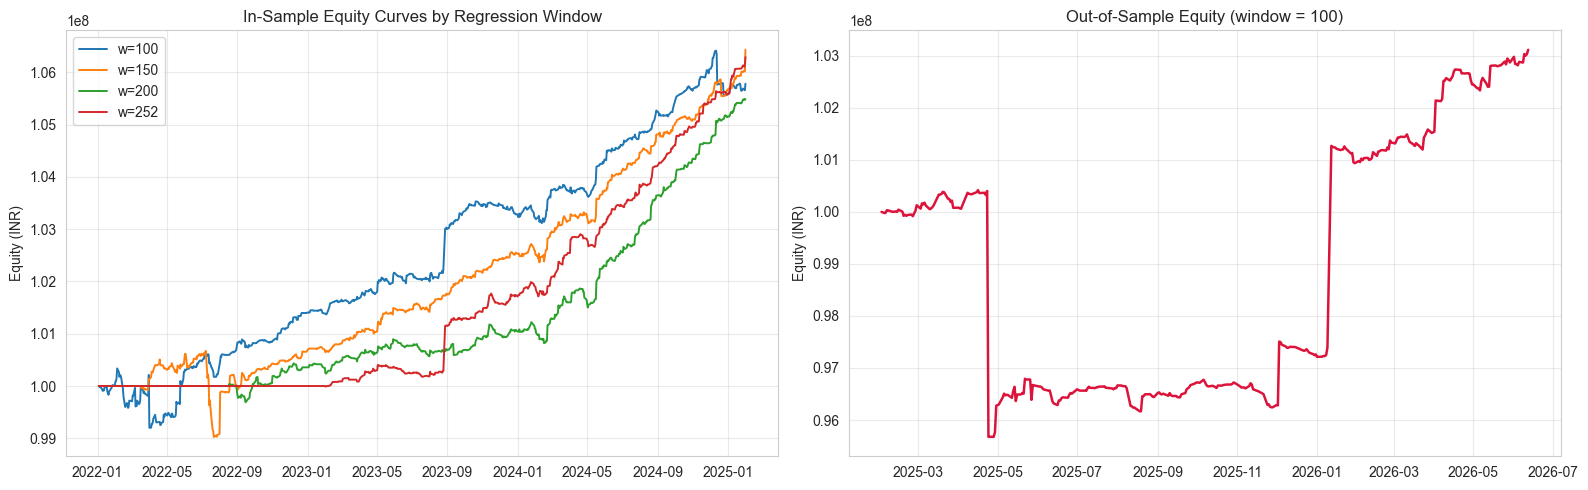

In [18]:
# 15.1 — Equity curves
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for w in cfg.REG_WINDOWS:
    ax[0].plot(is_results[w]["equity"], label=f"w={w}", linewidth=1.4)
ax[0].set_title("In-Sample Equity Curves by Regression Window")
ax[0].set_ylabel("Equity (INR)")
ax[0].legend()
ax[0].grid(True, alpha=0.4)

ax[1].plot(oos_equity, color="crimson", linewidth=1.8)
ax[1].set_title(f"Out-of-Sample Equity (window = {best_window})")
ax[1].set_ylabel("Equity (INR)")
ax[1].grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

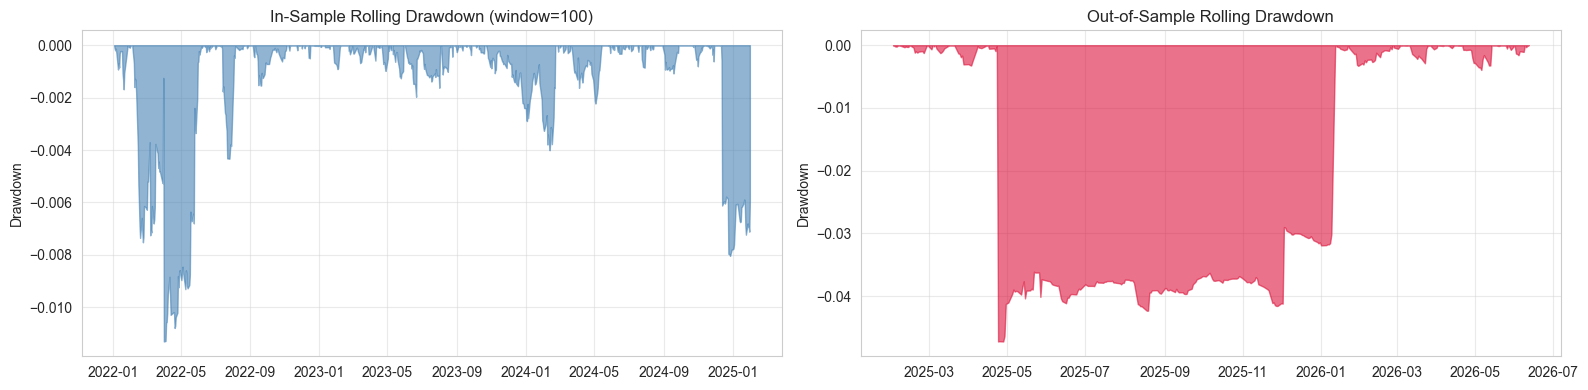

In [19]:
# 15.2 — Rolling drawdown (IS best window + OOS)
def drawdown(equity):
    return equity / equity.cummax() - 1

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
dd_is  = drawdown(is_results[best_window]["equity"])
dd_oos = drawdown(oos_equity)
ax[0].fill_between(dd_is.index, dd_is.values, 0, color="steelblue", alpha=0.6)
ax[0].set_title(f"In-Sample Rolling Drawdown (window={best_window})")
ax[1].fill_between(dd_oos.index, dd_oos.values, 0, color="crimson", alpha=0.6)
ax[1].set_title(f"Out-of-Sample Rolling Drawdown")
for a in ax:
    a.set_ylabel("Drawdown")
    a.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

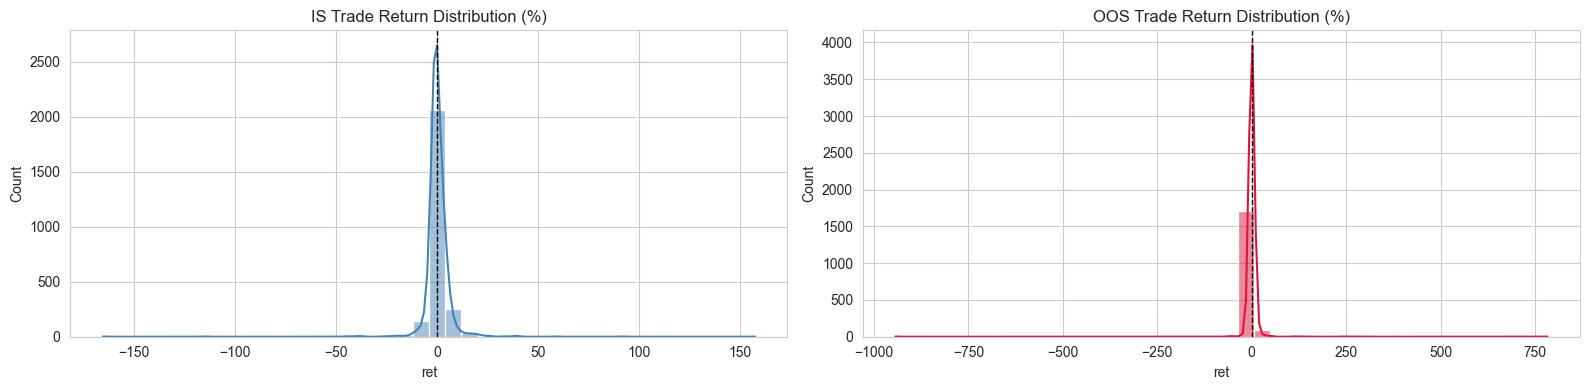

In [20]:
# 15.3 — Distribution of trade returns
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
is_tr  = is_results[best_window]["trades"]["ret"] * 100
oos_tr = oos_trades["ret"] * 100
sns.histplot(is_tr,  bins=40, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("IS Trade Return Distribution (%)")
ax[0].axvline(0, color="k", linestyle="--", linewidth=1)
sns.histplot(oos_tr, bins=40, kde=True, color="crimson", ax=ax[1])
ax[1].set_title("OOS Trade Return Distribution (%)")
ax[1].axvline(0, color="k", linestyle="--", linewidth=1)
plt.tight_layout(); plt.show()

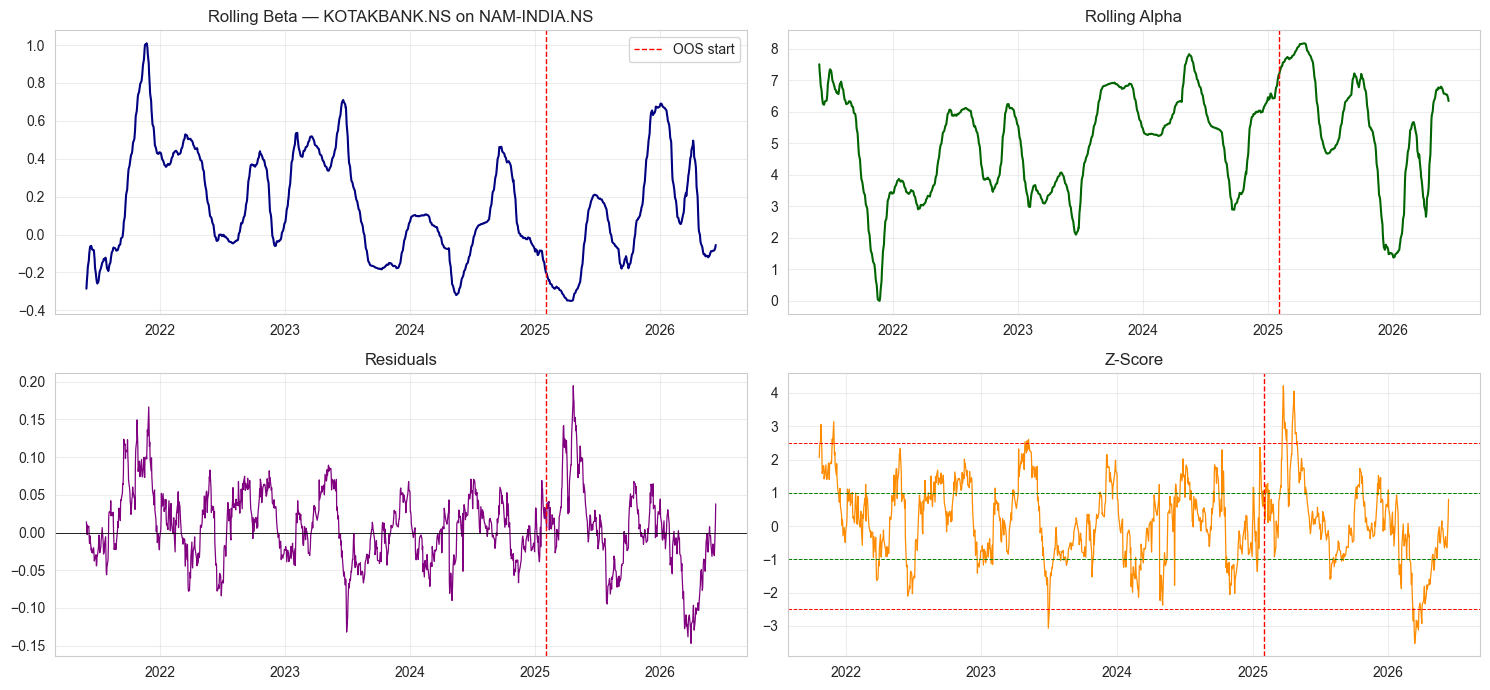

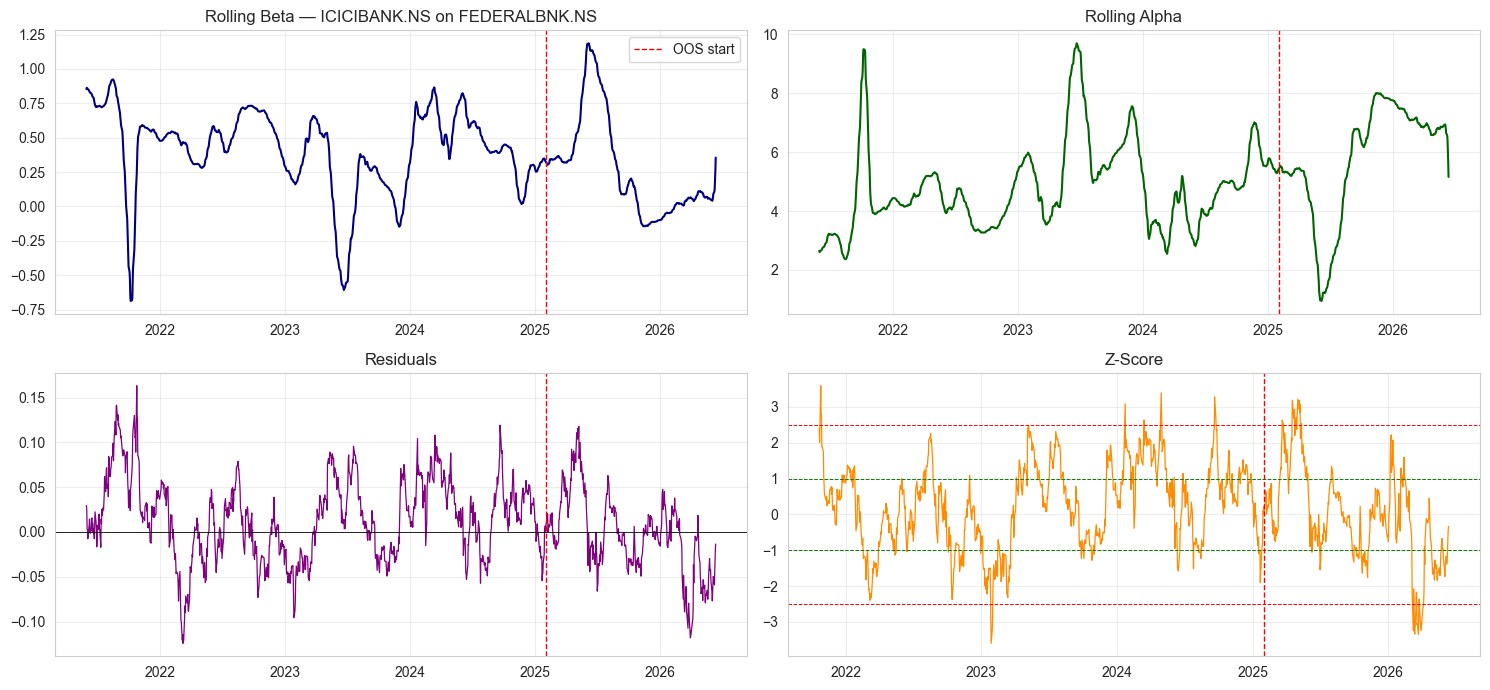

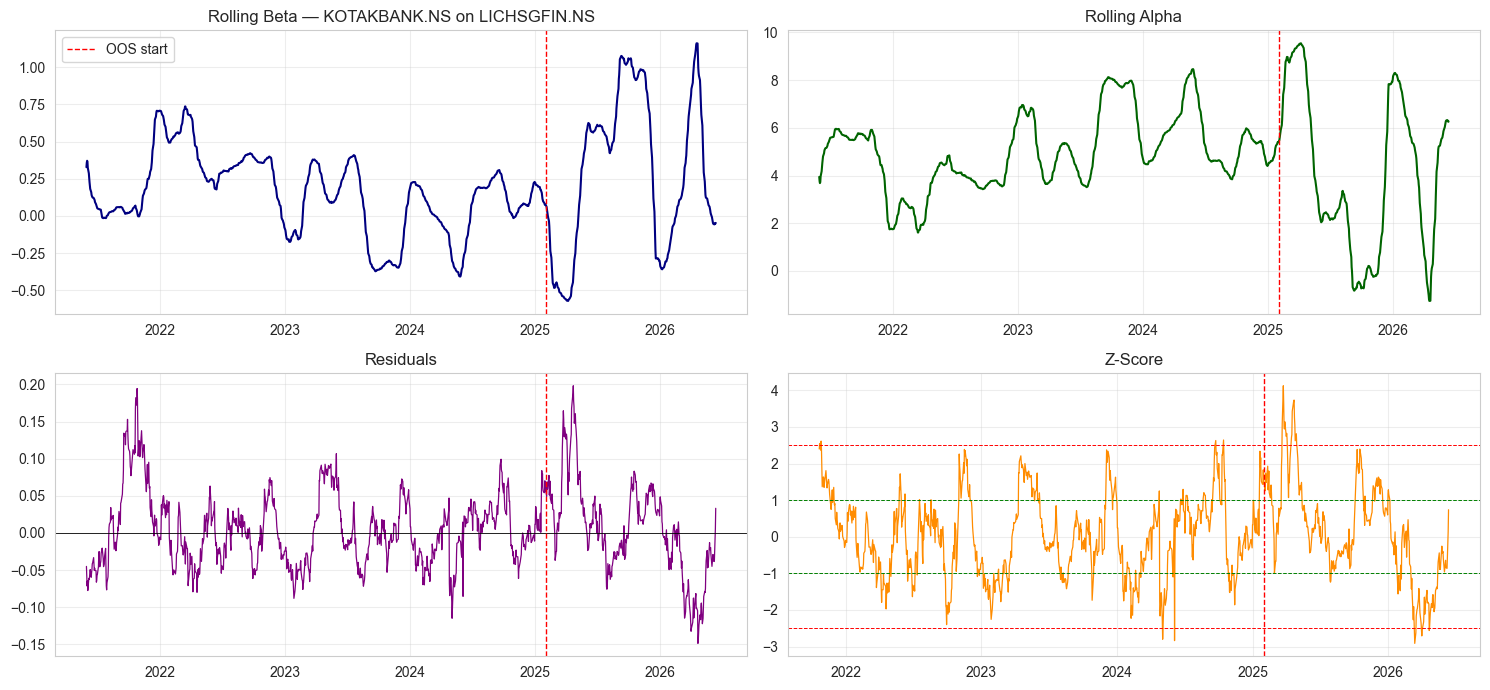

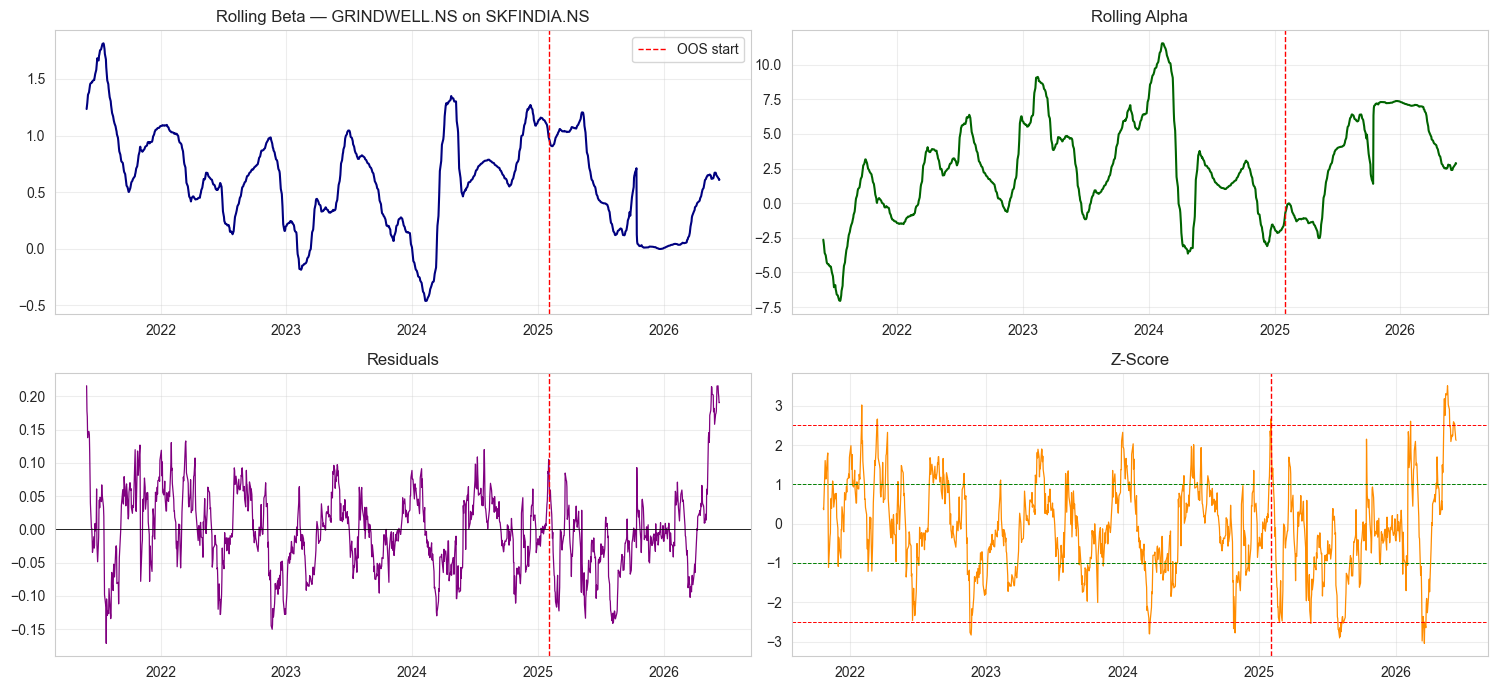

In [21]:
# 15.4 — Top pairs: rolling beta, alpha, residual, z
top_pairs = (pair_breakdown(is_results[best_window]["trades"])
             .head(4)[["Y","X"]].values.tolist())

for y, x in top_pairs:
    rs = rolling_store[(y, x)][best_window]
    fig, axes = plt.subplots(2, 2, figsize=(15, 7))
    axes[0,0].plot(rs.index, rs["beta"], color="navy")
    axes[0,0].set_title(f"Rolling Beta — {y} on {x}")
    axes[0,0].axvline(pd.Timestamp(cfg.OOS_START), color="red",
                      linestyle="--", linewidth=1, label="OOS start")
    axes[0,0].legend()

    axes[0,1].plot(rs.index, rs["alpha"], color="darkgreen")
    axes[0,1].set_title("Rolling Alpha")
    axes[0,1].axvline(pd.Timestamp(cfg.OOS_START), color="red",
                      linestyle="--", linewidth=1)

    axes[1,0].plot(rs.index, rs["resid"], color="purple", linewidth=0.9)
    axes[1,0].axhline(0, color="k", linewidth=0.6)
    axes[1,0].set_title("Residuals")
    axes[1,0].axvline(pd.Timestamp(cfg.OOS_START), color="red",
                      linestyle="--", linewidth=1)

    axes[1,1].plot(rs.index, rs["z"], color="darkorange", linewidth=0.9)
    for lvl, c in [(cfg.Z_ENTRY,"red"), (-cfg.Z_ENTRY,"red"),
                   (cfg.Z_EXIT,"green"), (-cfg.Z_EXIT,"green")]:
        axes[1,1].axhline(lvl, color=c, linestyle="--", linewidth=0.7)
    axes[1,1].set_title("Z-Score")
    axes[1,1].axvline(pd.Timestamp(cfg.OOS_START), color="red",
                      linestyle="--", linewidth=1)
    for a in axes.flat: a.grid(True, alpha=0.35)
    plt.tight_layout(); plt.show()

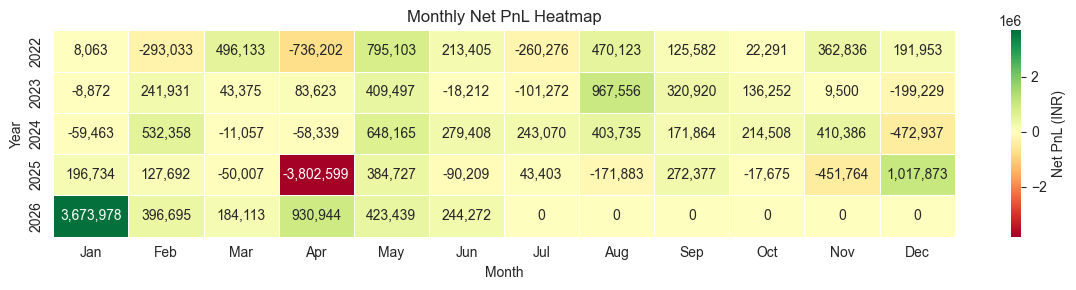

In [22]:
# 15.5 — Monthly PnL heatmap (IS + OOS concatenated)
tr = all_trades.copy()
tr["exit_date"] = pd.to_datetime(tr["exit_date"])
monthly = tr.groupby([tr["exit_date"].dt.year, tr["exit_date"].dt.month])["net_pnl"].sum()
monthly = monthly.unstack(fill_value=0)
monthly.columns = [pd.Timestamp(2000, m, 1).strftime("%b") for m in monthly.columns]

plt.figure(figsize=(12, max(3, 0.5*len(monthly))))
sns.heatmap(monthly, annot=True, fmt=",.0f", cmap="RdYlGn", center=0,
            linewidths=0.5, cbar_kws={"label": "Net PnL (INR)"})
plt.title("Monthly Net PnL Heatmap")
plt.ylabel("Year"); plt.xlabel("Month")
plt.tight_layout(); plt.show()

## 16 — Final Research Report

In [23]:
def fmt_pct(x): return f"{x:.2%}" if pd.notna(x) else "n/a"
def fmt_num(x): return f"{x:,.2f}" if pd.notna(x) else "n/a"
def fmt_int(x): return f"{int(x):,}" if pd.notna(x) else "n/a"

is_metr  = is_results[best_window]["metrics"]
oos_metr = oos_metrics

top_sharpe = (pair_breakdown(is_results[best_window]["trades"])
              .sort_values("sharpe",  ascending=False).head(20))
top_pnl    = (pair_breakdown(is_results[best_window]["trades"])
              .sort_values("net_pnl", ascending=False).head(20))
stable_top = stability.sort_values("beta_drift").head(15)

# Pre-compute string fragments so the f-string stays readable.
n_pairs        = len(pairs_df)
n_candidates   = f"{len(pair_candidates):,}"
n_coint        = int((coint_df['coint_pvalue'] < cfg.COINT_PVALUE_MAX).sum())
n_stable       = int(stability['still_coint'].sum())
n_stab_total   = len(stability)
stab_rate      = f"{stability['still_coint'].mean():.1%}"
sharpe_delta   = f"{(oos_metr['sharpe'] - is_metr['sharpe']):+.2f}"
pf_delta       = f"{(oos_metr['profit_factor'] - is_metr['profit_factor']):+.2f}"
wr_delta       = f"{(oos_metr['win_rate']      - is_metr['win_rate']):+.2%}"
agg_exposure   = f"{cfg.CAPITAL_PER_PAIR*n_pairs:,}"
is_compare_str = is_compare.round(3).to_string()
top_sharpe_str = top_sharpe[["Y","X","n_trades","win_rate","net_pnl",
                             "profit_factor","sharpe"]].round(3).to_string(index=False)
top_pnl_str    = top_pnl[["Y","X","n_trades","win_rate","net_pnl",
                          "profit_factor","sharpe"]].round(3).to_string(index=False)
stable_str     = stable_top.round(4).to_string(index=False)

report = f"""
================================================================================
  PAIR TRADING RESEARCH REPORT - NIFTY 500
  Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
================================================================================

1. UNIVERSE
   - Raw NIFTY 500 list           : {len(uni)}
   - Surviving post-clean         : {len(uni_clean)}
   - Trading days (full panel)    : {prices.shape[0]}
   - Date range                   : {prices.index.min().date()} -> {prices.index.max().date()}

2. PAIR DISCOVERY
   - Same-industry pre-filter     : {cfg.SAME_INDUSTRY_ONLY}
   - Candidate pairs tested       : {n_candidates}
   - Cointegrated (p<{cfg.COINT_PVALUE_MAX})        : {n_coint}
   - Pairs taken forward          : {n_pairs}

3. REGRESSION WINDOW COMPARISON (IN-SAMPLE)
{is_compare_str}
   >>> Best window selected: {best_window} <<<

4. IN-SAMPLE PERFORMANCE @ window={best_window}
   - Trades             : {fmt_int(is_metr['n_trades'])}
   - Win rate           : {fmt_pct(is_metr['win_rate'])}
   - Avg trade return   : {fmt_pct(is_metr['avg_ret'])}
   - Avg holding days   : {fmt_num(is_metr['avg_hold'])}
   - Total gross PnL    : INR {fmt_num(is_metr['total_pnl'])}
   - Total net PnL      : INR {fmt_num(is_metr['net_pnl'])}
   - Profit factor      : {fmt_num(is_metr['profit_factor'])}
   - Sharpe (ann)       : {fmt_num(is_metr['sharpe'])}
   - Sortino (ann)      : {fmt_num(is_metr['sortino'])}
   - Max drawdown       : {fmt_pct(is_metr['max_dd'])}

5. OUT-OF-SAMPLE PERFORMANCE @ window={best_window}
   - Trades             : {fmt_int(oos_metr['n_trades'])}
   - Win rate           : {fmt_pct(oos_metr['win_rate'])}
   - Avg trade return   : {fmt_pct(oos_metr['avg_ret'])}
   - Avg holding days   : {fmt_num(oos_metr['avg_hold'])}
   - Total gross PnL    : INR {fmt_num(oos_metr['total_pnl'])}
   - Total net PnL      : INR {fmt_num(oos_metr['net_pnl'])}
   - Profit factor      : {fmt_num(oos_metr['profit_factor'])}
   - Sharpe (ann)       : {fmt_num(oos_metr['sharpe'])}
   - Sortino (ann)      : {fmt_num(oos_metr['sortino'])}
   - Max drawdown       : {fmt_pct(oos_metr['max_dd'])}

6. COINTEGRATION STABILITY
   - Pairs still cointegrated OOS : {n_stable} / {n_stab_total} ({stab_rate})

7. TOP 20 PAIRS BY IN-SAMPLE SHARPE
{top_sharpe_str}

8. TOP 20 PAIRS BY IN-SAMPLE NET PnL
{top_pnl_str}

9. MOST BETA-STABLE PAIRS (lowest IS->OOS beta drift)
{stable_str}

10. ROBUSTNESS COMMENTARY
    - Sharpe degradation IS->OOS   : {sharpe_delta}
    - PF degradation IS->OOS       : {pf_delta}
    - Hit-rate degradation IS->OOS : {wr_delta}
    - Strategy is considered ROBUST if OOS Sharpe > 0.7 and PF > 1.2 with manageable DD.

11. KEY RISKS & LIMITATIONS
    - Survivorship bias from using current NIFTY 500 list, not historical constituents.
    - Engle-Granger assumes a *constant* cointegrating vector - empirically beta drifts.
    - Transaction costs modelled as flat bps; real Indian markets have STT, exchange
      fees, GST and impact cost which can run 25-60 bps round-trip on small caps.
    - No short-availability check - many NSE names cannot be reliably shorted
      intraday-only; SLB rates can erode edge.
    - No corporate-action / dividend handling beyond yfinance auto-adjust.
    - No regime filter (vol, market direction) - pair strategies historically suffer
      in trend-shock regimes (e.g. COVID drawdown, post-budget rallies).
    - Multiple-testing: scanning ~thousands of pairs and keeping p<0.05 by definition
      lets ~5% of *non-cointegrated* pairs through - Bonferroni-style adjustment
      recommended for live deployment.

12. POTENTIAL IMPROVEMENTS
    - Johansen test for multivariate / three-asset cointegration baskets.
    - Kalman-filtered hedge ratio instead of fixed-window OLS.
    - Half-life-based exit instead of fixed z thresholds.
    - Volatility-scaled position sizing (target risk per pair, not capital).
    - Stop-loss in PnL terms in addition to z-stop.
    - Walk-forward re-estimation of cointegration every 3-6 months instead of frozen
      IS set.

13. RECOMMENDATIONS FOR LIVE DEPLOYMENT
    - Paper-trade the top 10 pairs by OOS Sharpe for 60-90 days before risking capital.
    - Cap aggregate exposure to {n_pairs} pairs x {cfg.CAPITAL_PER_PAIR:,} = INR {agg_exposure};
      size down by Kelly-style fraction.
    - Re-run the cointegration screen monthly; retire pairs whose p-value crosses 0.10.
    - Add a portfolio-level kill-switch at 8-10% drawdown.
    - Monitor beta drift weekly; widen entry threshold or close the pair if |db| > 0.5.

================================================================================
"""
print(report)
with open(cfg.OUTPUT_DIR / "research_report.txt", "w") as f:
    f.write(report)
print(f"\nSaved -> {cfg.OUTPUT_DIR/'research_report.txt'}")


  PAIR TRADING RESEARCH REPORT - NIFTY 500
  Generated: 2026-08-11 07:16

1. UNIVERSE
   - Raw NIFTY 500 list           : 503
   - Surviving post-clean         : 448
   - Trading days (full panel)    : 1347
   - Date range                   : 2021-01-01 -> 2026-06-12

2. PAIR DISCOVERY
   - Same-industry pre-filter     : True
   - Candidate pairs tested       : 8,059
   - Cointegrated (p<0.05)        : 760
   - Pairs taken forward          : 200

3. REGRESSION WINDOW COMPARISON (IN-SAMPLE)
         n_trades  win_rate  avg_ret      total_pnl        net_pnl  profit_factor  sharpe  sortino  max_dd  avg_hold
window                                                                                                              
100    2,534.0000    0.4610   0.0050 8,305,322.7440 5,779,477.2260         1.3560 -4.0820  -5.2070 -0.0110    9.4700
150    1,735.0000    0.5000   0.0070 8,180,455.6470 6,429,144.2980         1.5770 -4.5930  -6.6270 -0.0160   11.1120
200    1,472.0000    0.4570   0.0070

## 17 — Output Files Recap

| File | Contents |
|---|---|
| `cointegrated_pairs.csv` | Surviving pairs with α, β, error ratio, p-value |
| `pair_summary.csv`       | Per-pair metrics split by IS / OOS |
| `trade_log.csv`          | Every trade ever opened, both periods, full state |
| `research_report.txt`    | Plain-text version of the final report |

All written to `./pair_trading_output/`.